In [2]:
!pip install gdown

In [3]:
import gdown

import pandas as pd

In [4]:
file_id = "1M7aRHzeR7HKjMz-kImOTRuA5S0VUE3Pp"

download_url = f"https://drive.google.com/uc?id={file_id}"

In [5]:
output_file = "Placed_dataset.csv"

In [6]:
gdown.download(download_url, output_file, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1M7aRHzeR7HKjMz-kImOTRuA5S0VUE3Pp
From (redirected): https://drive.google.com/uc?id=1M7aRHzeR7HKjMz-kImOTRuA5S0VUE3Pp&confirm=t&uuid=7c2a7c23-a762-4369-9c80-55adc12d80b9
To: /content/Placed_dataset.csv
100%|██████████| 181M/181M [00:03<00:00, 59.8MB/s]


'Placed_dataset.csv'

In [7]:
data = pd.read_csv(output_file)

# Improving Candidate Placement Success Rate

## Business Context

Placed is a hiring agency aiming to improve placement conversion rates by understanding factors affecting student placements.

## North Star Metric

Placement Success Rate

Placement Success Rate = Placed Students / Total Students

## Objectives

- Identify factors affecting placement
- Improve candidate shortlisting
- Guide students on preparation strategy
- Improve recruiter efficiency

In [8]:
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

In [9]:
data.head()

,age,cgpa,backlogs,attendance,tenth_percentage,twelfth_percentage,branch,college_tier,python_skill,c++_skill,...,certifications,coding_contest_rating,teamwork,leadership,problem_solving,time_management,gender,city_tier,family_income,placed
0,23,7.94,3,84.656624,81.551017,54.282095,CSE,2,9,8,...,0,756.826630,5,9,9,2,Female,1,7.849912,1
1,24,7.46,2,90.663809,71.742919,61.844316,IT,3,7,6,...,1,1008.725810,3,1,4,8,Female,2,8.621398,1
2,22,7.17,2,84.895718,87.972353,80.510087,CSE,1,3,2,...,2,1053.419286,6,0,6,5,Female,3,4.046578,0
3,24,8.27,2,69.347246,72.739454,88.699314,ECE,1,2,5,...,3,1194.295018,9,1,9,9,Female,2,8.676290,1
4,24,8.34,2,74.225862,45.648440,77.383406,CSE,2,3,1,...,1,1182.628600,9,0,7,7,Male,3,6.996345,0


# Dataset structure


In [10]:
data.shape

(1000000, 30)

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 30 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   age                    1000000 non-null  int64  
 1   cgpa                   1000000 non-null  float64
 2   backlogs               1000000 non-null  int64  
 3   attendance             1000000 non-null  float64
 4   tenth_percentage       1000000 non-null  float64
 5   twelfth_percentage     1000000 non-null  float64
 6   branch                 1000000 non-null  object 
 7   college_tier           1000000 non-null  int64  
 8   python_skill           1000000 non-null  int64  
 9   c++_skill              1000000 non-null  int64  
 10  java_skill             1000000 non-null  int64  
 11  ml_skill               1000000 non-null  int64  
 12  web_dev_skill          1000000 non-null  int64  
 13  communication_skill    1000000 non-null  int64  
 14  aptitude_score     

In [12]:
data.describe()

,age,cgpa,backlogs,attendance,tenth_percentage,twelfth_percentage,college_tier,python_skill,c++_skill,java_skill,...,hackathons,certifications,coding_contest_rating,teamwork,leadership,problem_solving,time_management,city_tier,family_income,placed
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,...,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,22.500194,7.499208,1.200309,79.923544,77.956957,74.915697,2.000118,4.503381,4.503944,4.501439,...,0.998496,1.997867,1200.028210,4.499140,4.496364,4.501241,4.497319,2.000799,8.007746,0.500159
std,1.707373,0.988203,1.094803,9.801409,9.871486,11.785236,0.816557,2.873744,2.871332,2.871802,...,0.999361,1.416061,399.867290,2.870049,2.872036,2.872764,2.873606,0.816499,2.973567,0.500000
min,20.000000,5.000000,0.000000,40.000000,40.000000,40.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,21.000000,6.830000,0.000000,73.249464,71.267875,66.889926,1.000000,2.000000,2.000000,2.000000,...,0.000000,1.000000,929.025586,2.000000,2.000000,2.000000,2.000000,1.000000,5.972419,0.000000
50%,23.000000,7.500000,1.000000,80.003117,78.010477,74.987332,2.000000,5.000000,5.000000,5.000000,...,1.000000,2.000000,1199.794028,5.000000,4.000000,5.000000,4.000000,2.000000,7.998021,1.000000
75%,24.000000,8.170000,2.000000,86.750697,84.744644,83.094789,3.000000,7.000000,7.000000,7.000000,...,2.000000,3.000000,1470.289975,7.000000,7.000000,7.000000,7.000000,3.000000,10.022507,1.000000
max,25.000000,10.000000,10.000000,100.000000,100.000000,100.000000,3.000000,9.000000,9.000000,9.000000,...,8.000000,12.000000,3000.000000,9.000000,9.000000,9.000000,9.000000,3.000000,23.480764,1.000000


# Placement distribution

In [13]:
data['placed'].value_counts()

,count
placed,
1,500159
0,499841


In [14]:
data["placed"].value_counts(normalize=True)*100

,proportion
placed,
1,50.0159
0,49.9841


# North star metric

In [15]:
placement_rate=(
data["placed"].sum()/len(data)
)*100

print("Placement Rate:",round(placement_rate,2),"%")

Placement Rate: 50.02 %


#### Placement success rate is 50.02%

## Hypotheses

H1: Higher CGPA increases placement chances

H2: Students with internships are more likely to be placed

H3: Communication skills positively affect placement

H4: Students from Tier-1 colleges have better placement rates

H5: Backlogs reduce placement probability

H6: Students with projects and certifications have better placement rates

# Checking missing values

In [16]:
data.isnull().sum()

,0
age,0
cgpa,0
backlogs,0
attendance,0
tenth_percentage,0
twelfth_percentage,0
branch,0
college_tier,0
python_skill,0
c++_skill,0


#### No missing values

# Checking for duplicates

In [17]:
data.duplicated().sum()

np.int64(0)

##### No duplicated value

# Creating sample for visualization

In [18]:
df=data.sample(
50000,
random_state=42
)

# Placement distribution

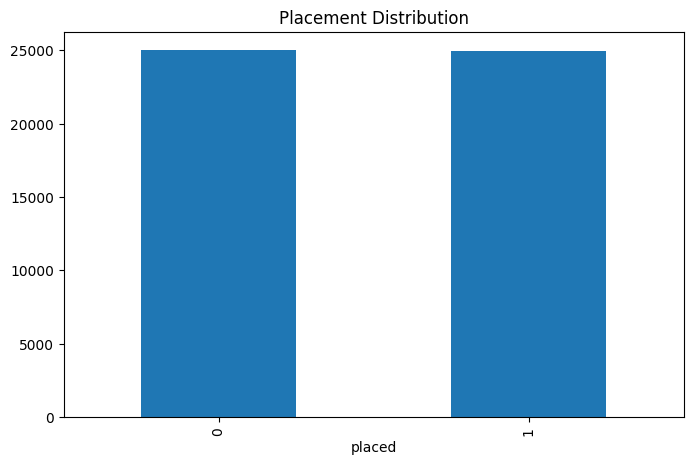

In [19]:
plt.figure(figsize=(8,5))

df["placed"].value_counts().plot(
kind='bar'
)

plt.title(
"Placement Distribution"
)

plt.show()

# CGPA distribution

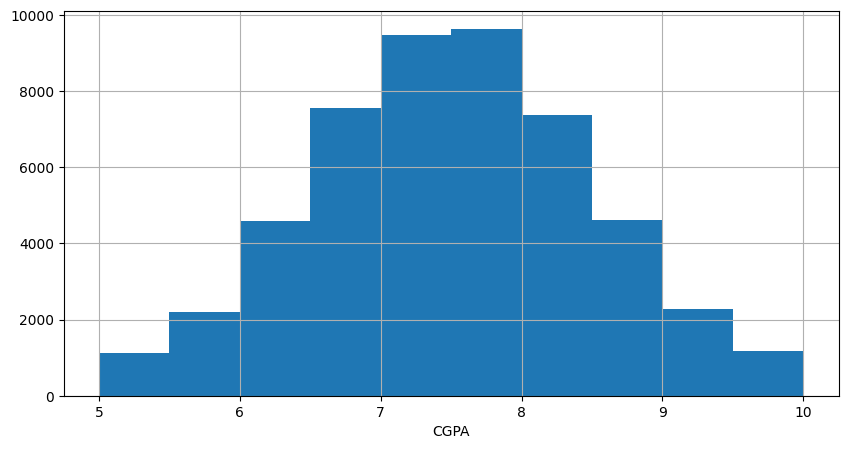

In [20]:
plt.figure(figsize=(10,5))

df["cgpa"].hist()

plt.xlabel("CGPA")

plt.show()

# Branch distribution

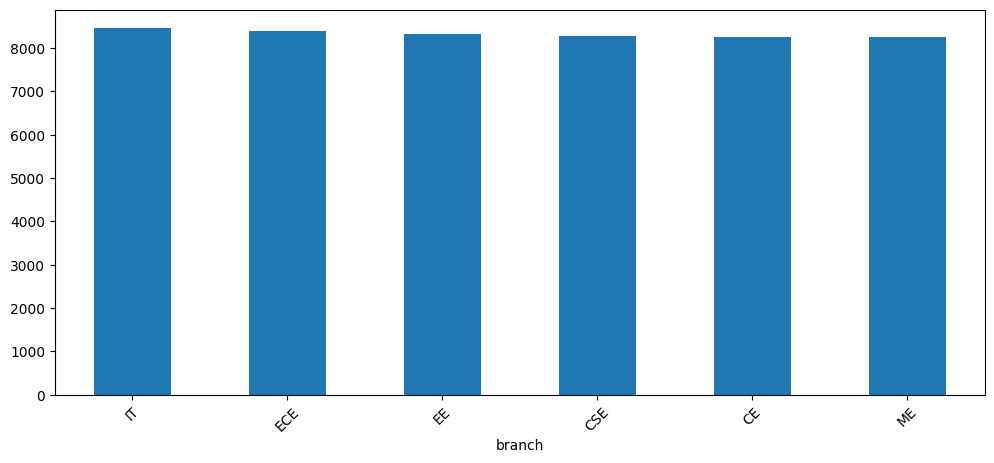

In [21]:
plt.figure(figsize=(12,5))

df["branch"].value_counts().plot(
kind='bar'
)

plt.xticks(rotation=45)

plt.show()

# CGPA vs Placement

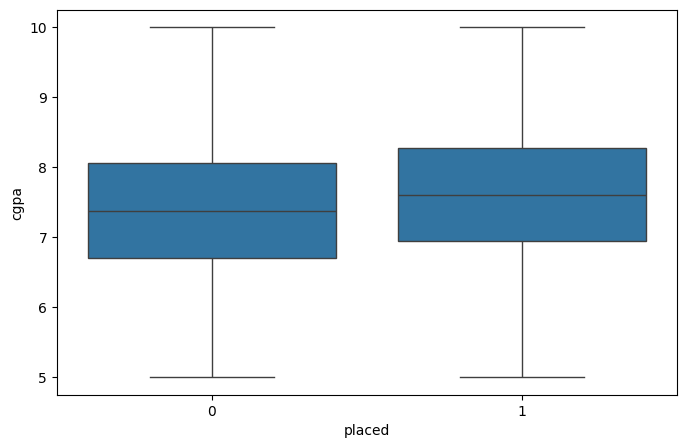

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(
x='placed',
y='cgpa',
data=df
)

plt.show()

#### Median CGPA for placed students is higher, therefore our hypothesis is supported.


# Internship vs placement

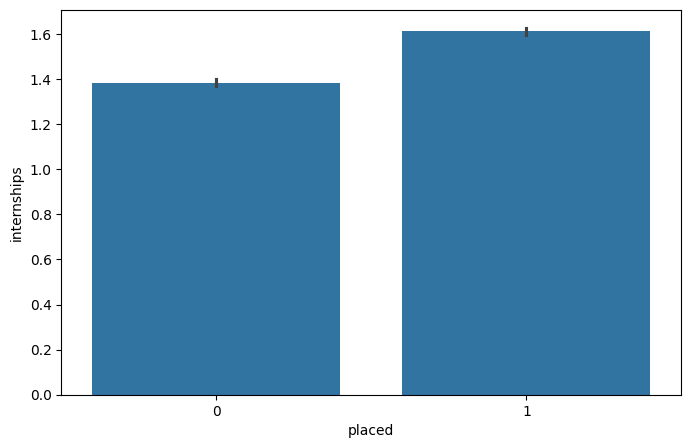

In [23]:
plt.figure(figsize=(8,5))

sns.barplot(
x='placed',
y='internships',
data=df
)

plt.show()

#### Placed students have higher number of internships.

# Communication skill vs placement

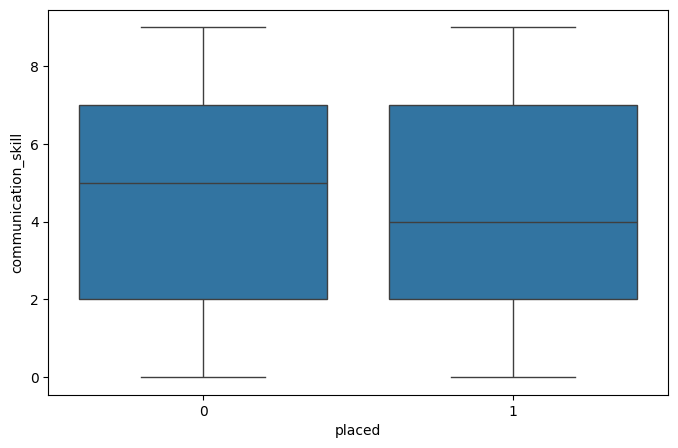

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(
x='placed',
y='communication_skill',
data=df
)

plt.show()

Here placed students have lower communication skill ability, negating our hypothesis.

# Backlog vs placement

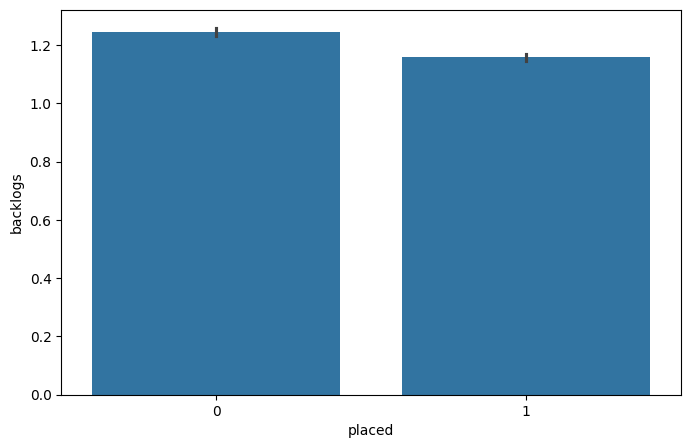

In [25]:
plt.figure(figsize=(8,5))

sns.barplot(
x='placed',
y='backlogs',
data=df
)

plt.show()

Placed students have lower number of backlogs , thus supporting our hypothesis.

# Correlation analysis

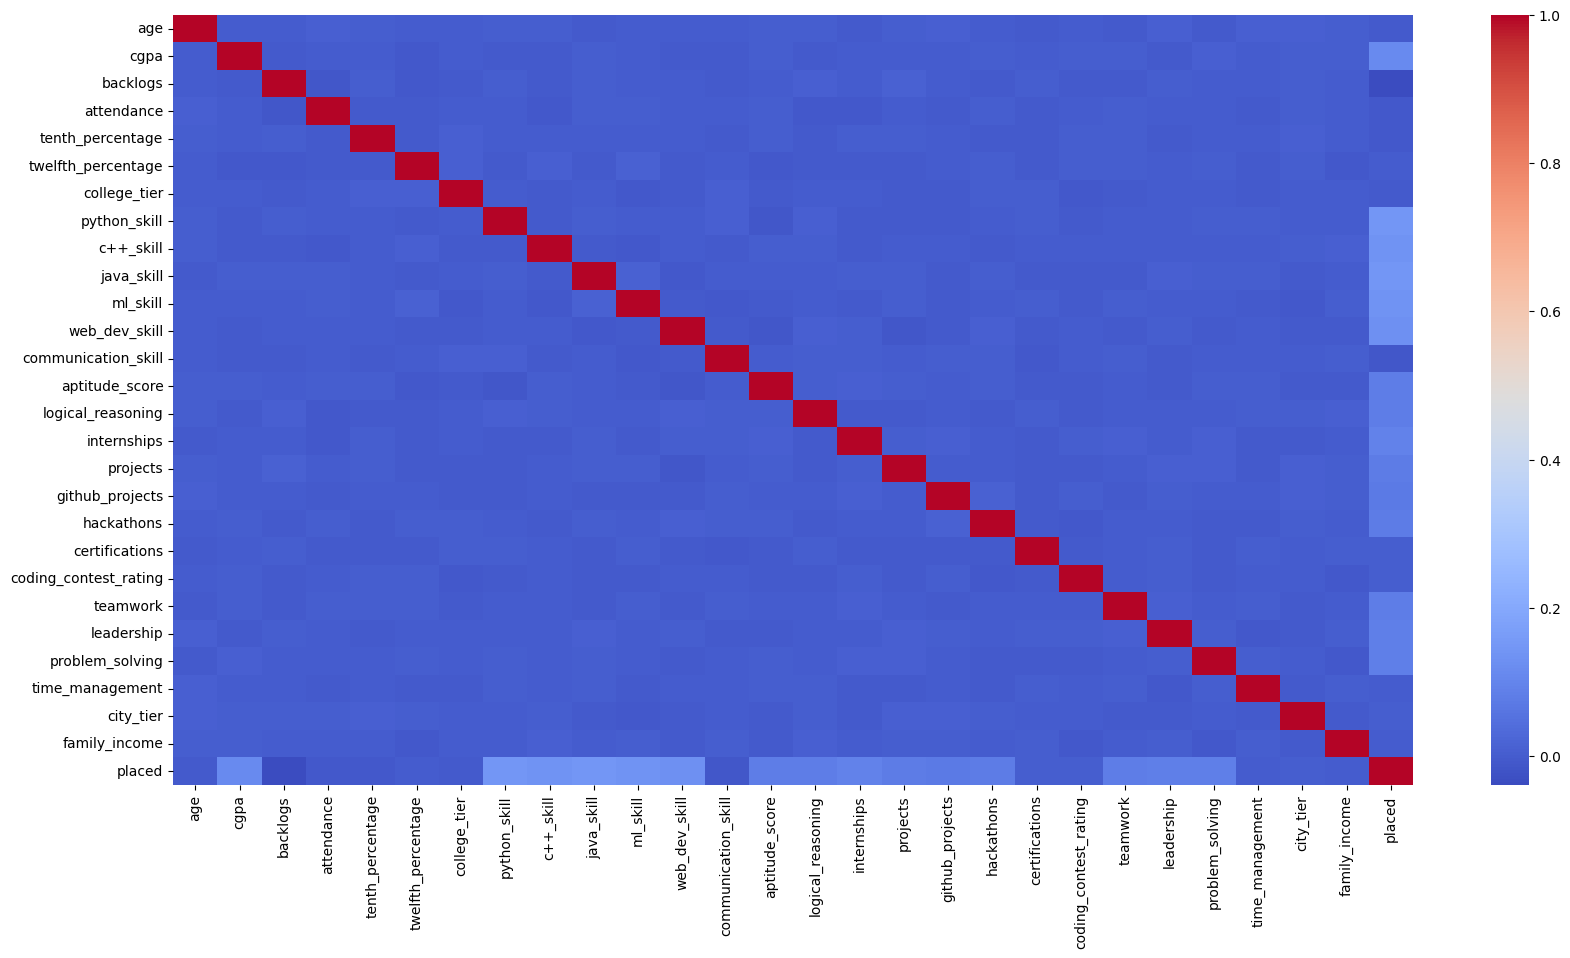

In [26]:
corr=df.corr(
numeric_only=True
)

plt.figure(
figsize=(20,10)
)

sns.heatmap(
corr,
cmap='coolwarm'
)

plt.show()

Students with stronger skills and practical experience
tend to have better placement outcomes.

Backlogs negatively affect placements.

# strongest factors affecting placement

In [27]:
corr["placed"].sort_values(
ascending=False
)

,placed
placed,1.000000
python_skill,0.144544
java_skill,0.144294
c++_skill,0.138720
ml_skill,0.136628
web_dev_skill,0.129392
cgpa,0.113718
internships,0.093021
leadership,0.083897
problem_solving,0.083579


# Candidate segmentation

In [28]:
df["candidate_score"]=(
df["cgpa"]
+
df["internships"]
+
df["projects"]
+
df["problem_solving"]
)

In [29]:
df["candidate_segment"]=pd.qcut(
df["candidate_score"],
q=3,
labels=[
"Low",
"Medium",
"High"
]
)

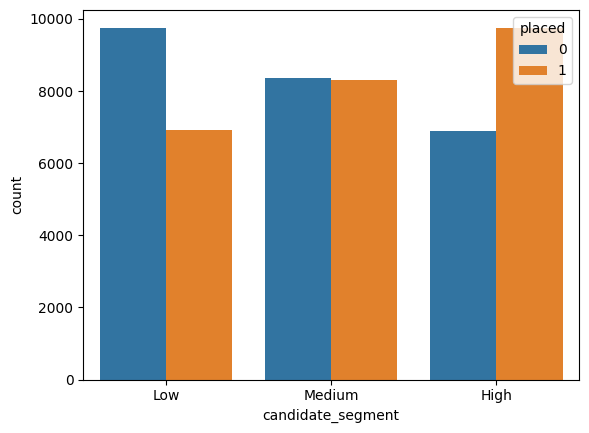

In [30]:
sns.countplot(
x='candidate_segment',
hue='placed',
data=df
)

plt.show()

In [31]:
data.to_csv(
"cleaned_placed.csv",
index=False
)

KeyboardInterrupt: 

In [32]:
data["candidate_score"]=(
data["cgpa"]
+
data["internships"]
+
data["projects"]
+
data["communication_skill"]
+
data["problem_solving"]
)

data["candidate_segment"]=pd.qcut(
data["candidate_score"],
q=3,
labels=["Low","Medium","High"]
)

In [33]:
data.to_csv(
"cleaned_placed.csv",
index=False
)